In [1]:
from ucimlrepo import fetch_ucirepo

credit_card = fetch_ucirepo(id=350)

X = credit_card.data.features
y = credit_card.data.targets

print("Features shape:", X.shape)
print("Target shape:", y.shape)

DatasetNotFoundError: Error reading data csv file for "Default of Credit Card Clients" dataset (id=350).

In [2]:
import sys

print(sys.executable)

/Users/raghad/Desktop/FinSight-AI/.venv/bin/python


In [3]:
import pandas as pd

file_path = "../data/raw/default of credit card clients.xls"

df = pd.read_excel(file_path, header=1)

print("Dataset shape:", df.shape)

Dataset shape: (30000, 25)


In [4]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [5]:
print(df.columns.tolist())

['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']


In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

In [8]:
df.isnull().sum()

ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

In [9]:
df["default payment next month"].value_counts()

default payment next month
0    23364
1     6636
Name: count, dtype: int64

In [10]:
df["default payment next month"].value_counts(normalize=True) * 100

default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64

Matplotlib is building the font cache; this may take a moment.


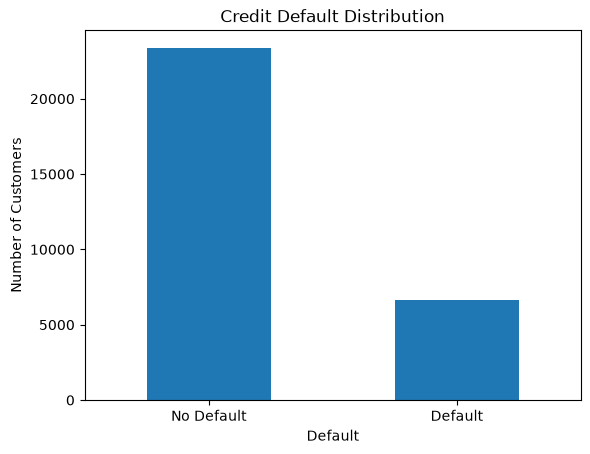

In [11]:
import matplotlib.pyplot as plt

df["default payment next month"].value_counts().plot(kind="bar")

plt.title("Credit Default Distribution")
plt.xlabel("Default")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ["No Default", "Default"], rotation=0)
plt.show()

In [12]:
df["EDUCATION"].value_counts().sort_index()

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

In [13]:
df["MARRIAGE"].value_counts().sort_index()

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

In [14]:
df["SEX"].value_counts().sort_index()

SEX
1    11888
2    18112
Name: count, dtype: int64

In [15]:
for col in ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())


PAY_0
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

PAY_2
PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64

PAY_3
PAY_3
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64

PAY_4
PAY_4
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7       58
 8        2
Name: count, dtype: int64

PAY_5
PAY_5
-2     4546
-1     5539
 0    16947
 2     2626
 3      178
 4       84
 5       17
 6        4
 7       58
 8        1
Name: count, dtype: int64

PAY_6
PAY_6
-2     4895
-1     5740
 0    16286
 2     2766
 3      184
 4       49
 5       13
 6       19
 7       46
 8        2
Name: count, dtype: int6

In [16]:
for col in ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]:
    print(f"\n{col}:")
    print(df[col].value_counts().sort_index().to_string())


PAY_0:
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19

PAY_2:
PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1

PAY_3:
PAY_3
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3

PAY_4:
PAY_4
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7       58
 8        2

PAY_5:
PAY_5
-2     4546
-1     5539
 0    16947
 2     2626
 3      178
 4       84
 5       17
 6        4
 7       58
 8        1

PAY_6:
PAY_6
-2     4895
-1     5740
 0    16286
 2     2766
 3      184
 4       49
 5       13
 6       19
 7       46
 8        2


In [17]:
for col in ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]:
    print(col, "→ min:", df[col].min(), "| max:", df[col].max())

PAY_0 → min: -2 | max: 8
PAY_2 → min: -2 | max: 8
PAY_3 → min: -2 | max: 8
PAY_4 → min: -2 | max: 8
PAY_5 → min: -2 | max: 8
PAY_6 → min: -2 | max: 8


In [18]:
for col in ["LIMIT_BAL", "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
            "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
            "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
            "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"]:
    print(col, "→ min:", df[col].min(), "| max:", df[col].max())

LIMIT_BAL → min: 10000 | max: 1000000
BILL_AMT1 → min: -165580 | max: 964511
BILL_AMT2 → min: -69777 | max: 983931
BILL_AMT3 → min: -157264 | max: 1664089
BILL_AMT4 → min: -170000 | max: 891586
BILL_AMT5 → min: -81334 | max: 927171
BILL_AMT6 → min: -339603 | max: 961664
PAY_AMT1 → min: 0 | max: 873552
PAY_AMT2 → min: 0 | max: 1684259
PAY_AMT3 → min: 0 | max: 896040
PAY_AMT4 → min: 0 | max: 621000
PAY_AMT5 → min: 0 | max: 426529
PAY_AMT6 → min: 0 | max: 528666


In [19]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df["ID"].nunique()

30000

In [22]:
X = df.drop(columns=["ID", "default payment next month"])
y = df["default payment next month"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (30000, 23)
y shape: (30000,)


In [23]:
print("EDUCATION unexpected values:")
print(df[~df["EDUCATION"].isin([1, 2, 3, 4])]["EDUCATION"].value_counts().sort_index())

print("\nMARRIAGE unexpected values:")
print(df[~df["MARRIAGE"].isin([1, 2, 3])]["MARRIAGE"].value_counts().sort_index())

EDUCATION unexpected values:
EDUCATION
0     14
5    280
6     51
Name: count, dtype: int64

MARRIAGE unexpected values:
MARRIAGE
0    54
Name: count, dtype: int64


In [24]:
print("Default rate by EDUCATION:")
print(
    df.groupby("EDUCATION")["default payment next month"]
    .agg(["count", "mean"])
)

print("\nDefault rate by MARRIAGE:")
print(
    df.groupby("MARRIAGE")["default payment next month"]
    .agg(["count", "mean"])
)

Default rate by EDUCATION:
           count      mean
EDUCATION                 
0             14  0.000000
1          10585  0.192348
2          14030  0.237349
3           4917  0.251576
4            123  0.056911
5            280  0.064286
6             51  0.156863

Default rate by MARRIAGE:
          count      mean
MARRIAGE                 
0            54  0.092593
1         13659  0.234717
2         15964  0.209283
3           323  0.260062


In [25]:
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

for col in pay_cols:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index().to_dict())


PAY_0
{-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}

PAY_2
{-2: 3782, -1: 6050, 0: 15730, 1: 28, 2: 3927, 3: 326, 4: 99, 5: 25, 6: 12, 7: 20, 8: 1}

PAY_3
{-2: 4085, -1: 5938, 0: 15764, 1: 4, 2: 3819, 3: 240, 4: 76, 5: 21, 6: 23, 7: 27, 8: 3}

PAY_4
{-2: 4348, -1: 5687, 0: 16455, 1: 2, 2: 3159, 3: 180, 4: 69, 5: 35, 6: 5, 7: 58, 8: 2}

PAY_5
{-2: 4546, -1: 5539, 0: 16947, 2: 2626, 3: 178, 4: 84, 5: 17, 6: 4, 7: 58, 8: 1}

PAY_6
{-2: 4895, -1: 5740, 0: 16286, 2: 2766, 3: 184, 4: 49, 5: 13, 6: 19, 7: 46, 8: 2}


In [26]:
unexpected_rows = df[
    (~df["EDUCATION"].isin([1, 2, 3, 4])) |
    (~df["MARRIAGE"].isin([1, 2, 3]))
]

print("Rows with unexpected categorical values:", len(unexpected_rows))

Rows with unexpected categorical values: 399


In [27]:
df_clean = df.copy()

print("Original shape:", df.shape)
print("Cleaning copy shape:", df_clean.shape)

Original shape: (30000, 25)
Cleaning copy shape: (30000, 25)


In [28]:
df_clean["EDUCATION"] = df_clean["EDUCATION"].replace({
    5: 0,
    6: 0
})

df_clean["MARRIAGE"] = df_clean["MARRIAGE"].replace({
    0: 0
})

print("EDUCATION values:")
print(df_clean["EDUCATION"].value_counts().sort_index())

print("\nMARRIAGE values:")
print(df_clean["MARRIAGE"].value_counts().sort_index())

EDUCATION values:
EDUCATION
0      345
1    10585
2    14030
3     4917
4      123
Name: count, dtype: int64

MARRIAGE values:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


In [29]:
df_clean = df.copy()

print(df_clean["EDUCATION"].value_counts().sort_index())
print()
print(df_clean["MARRIAGE"].value_counts().sort_index())

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


In [30]:
print("AGE range:")
print("Minimum:", df_clean["AGE"].min())
print("Maximum:", df_clean["AGE"].max())

print("\nAGE values below 18:")
print((df_clean["AGE"] < 18).sum())

AGE range:
Minimum: 21
Maximum: 79

AGE values below 18:
0


In [31]:
bill_cols = [
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"
]

for col in bill_cols:
    negative_count = (df_clean[col] < 0).sum()
    print(col, "→ negative values:", negative_count)

BILL_AMT1 → negative values: 590
BILL_AMT2 → negative values: 669
BILL_AMT3 → negative values: 655
BILL_AMT4 → negative values: 675
BILL_AMT5 → negative values: 655
BILL_AMT6 → negative values: 688


In [32]:
df_clean.loc[
    df_clean["BILL_AMT1"] < 0,
    ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1", "default payment next month"]
].head(10)

,LIMIT_BAL,BILL_AMT1,PAY_AMT1,default payment next month
26,60000,-109,0,1
68,130000,-190,0,0
92,100000,-2000,7555,0
101,380000,-81,223,0
109,360000,-103,0,0
149,260000,-1100,0,0
173,50000,-709,0,1
216,240000,-946,0,1
319,180000,-2,0,0
330,200000,-179,1000,1


In [33]:
pay_amt_cols = [
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]

for col in pay_amt_cols:
    negative_count = (df_clean[col] < 0).sum()
    print(col, "→ negative values:", negative_count)

PAY_AMT1 → negative values: 0
PAY_AMT2 → negative values: 0
PAY_AMT3 → negative values: 0
PAY_AMT4 → negative values: 0
PAY_AMT5 → negative values: 0
PAY_AMT6 → negative values: 0


In [34]:
df_clean.groupby("default payment next month")["LIMIT_BAL"].mean()

default payment next month
0    178099.726074
1    130109.656420
Name: LIMIT_BAL, dtype: float64

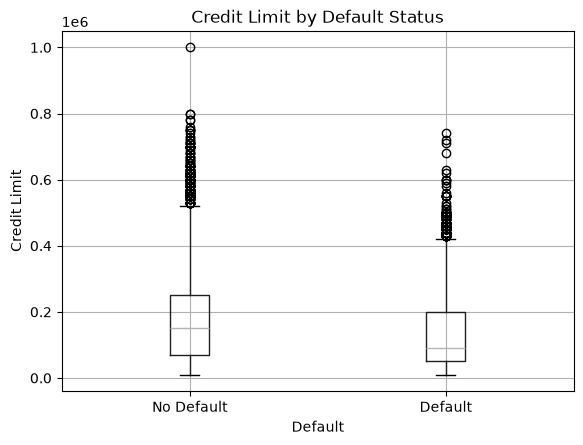

In [35]:
import matplotlib.pyplot as plt

df_clean.boxplot(
    column="LIMIT_BAL",
    by="default payment next month"
)

plt.title("Credit Limit by Default Status")
plt.suptitle("")
plt.xlabel("Default")
plt.ylabel("Credit Limit")
plt.xticks([1, 2], ["No Default", "Default"])

plt.show()

In [36]:
df_clean.groupby("default payment next month")["PAY_0"].mean()

default payment next month
0   -0.211222
1    0.668174
Name: PAY_0, dtype: float64

In [37]:
default_rate_by_pay0 = (
    df_clean.groupby("PAY_0")["default payment next month"]
    .mean()
    .mul(100)
)

print(default_rate_by_pay0)

PAY_0
-2    13.229431
-1    16.778051
 0    12.811291
 1    33.947939
 2    69.141357
 3    75.776398
 4    68.421053
 5    50.000000
 6    54.545455
 7    77.777778
 8    57.894737
Name: default payment next month, dtype: float64


In [38]:
df_clean.groupby("default payment next month")["AGE"].agg(["mean", "median"])

,mean,median
default payment next month,,
0,35.417266,34.0
1,35.725738,34.0


In [39]:
default_rate_by_education = (
    df_clean.groupby("EDUCATION")["default payment next month"]
    .mean()
    .mul(100)
)

print(default_rate_by_education)

EDUCATION
0     0.000000
1    19.234766
2    23.734854
3    25.157616
4     5.691057
5     6.428571
6    15.686275
Name: default payment next month, dtype: float64


In [40]:
default_rate_by_marriage = (
    df_clean.groupby("MARRIAGE")["default payment next month"]
    .mean()
    .mul(100)
)

print(default_rate_by_marriage)

MARRIAGE
0     9.259259
1    23.471704
2    20.928339
3    26.006192
Name: default payment next month, dtype: float64


In [41]:
bill_cols = [
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6"
]

df_clean["AVG_BILL_AMT"] = df_clean[bill_cols].mean(axis=1)

print(
    df_clean.groupby("default payment next month")["AVG_BILL_AMT"]
    .agg(["mean", "median"])
)

                                    mean        median
default payment next month                            
0                           45404.817975  21443.416667
1                           43470.492591  19781.333333


In [42]:
pay_cols = [
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"
]

df_clean["AVG_PAY_AMT"] = df_clean[pay_cols].mean(axis=1)

print(
    df_clean.groupby("default payment next month")["AVG_PAY_AMT"]
    .agg(["mean", "median"])
)

                                   mean       median
default payment next month                          
0                           5828.236775  2754.000000
1                           3328.215617  1612.416667


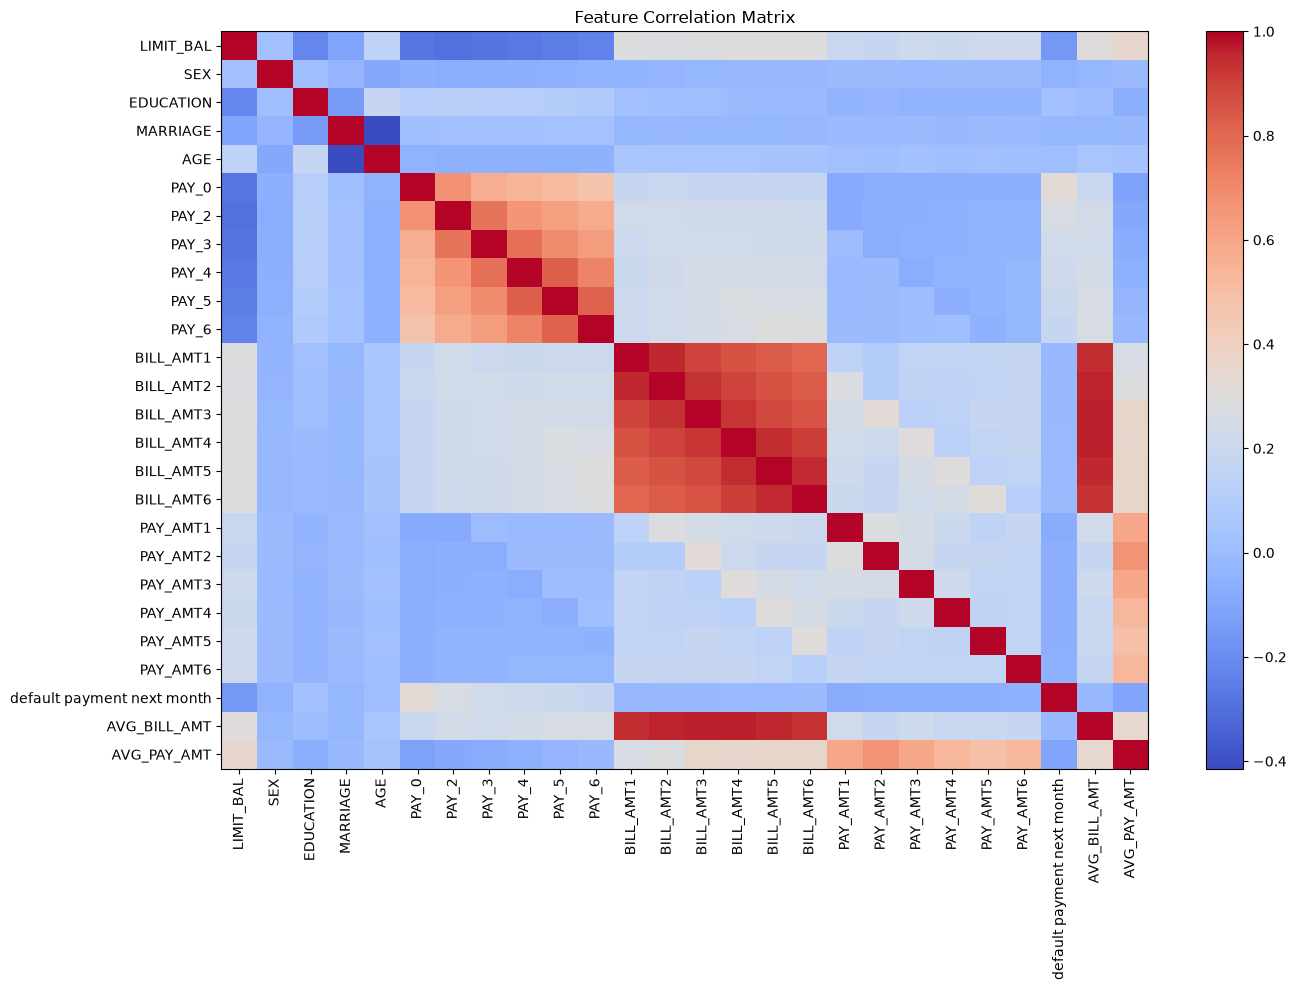

In [43]:
correlation = df_clean.drop(
    columns=["ID"]
).corr()

plt.figure(figsize=(14, 10))
plt.imshow(correlation, cmap="coolwarm", aspect="auto")
plt.colorbar()
plt.title("Feature Correlation Matrix")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)
plt.tight_layout()
plt.show()